# Visium HD demo data: data-driven analysis buffer (paper section 2)

All public 10x Visium HD datasets processed with "v1 - Protocol 2.0" that have an H&E image
(11 datasets; human, mouse, rat), at 8 µm. Spot-based border: tissue footprint from Space Ranger's
filtered bins, bosperrus piecewise-linear elbow per connected component, BLADE before and after
bosperrus correction. The paired Visium HD / Stereo-seq comparison (section 3) is in `ST_paired.ipynb`.

Everything is read from `results/spatial_omics/st_reroll/`, written on a compute node by
`src/spatial_omics/st_precompute.py` (`jobs/spatial_omics_st_precompute.sbatch <sample>`;
the image-mask supplement needs `--image-mask`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from bosperrus import FIT_PALETTE, plot_fit
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Everything below reads precomputed per-sample results -- written on a compute
# node by src/spatial_omics/st_precompute.py (see st_precompute.sbatch), which runs
# bosperrus.load_filtered + identify_analysis_buffer_from_filtered (+ BLADE) and
# bosperrus.quantify_diffusion_from_raw at 8um for every sample in st_samples.csv.
RESULTS_DIR = Path("../../results/spatial_omics/st_reroll")
SAMPLES = pd.read_csv("../../src/spatial_omics/st_samples.csv")

SAMPLES = SAMPLES[SAMPLES["dataset_type"] == "visium_demo"].reset_index(drop=True)
print(len(SAMPLES), "demo samples:", ", ".join(SAMPLES["name"]))

11 demo samples: breast_cancer, pancreas, colon_cancer_ff, breast_cancer_tma, rat_liver, brain_cancer, tissue_array, colon_cancer_6p5mm, heart, mouse_brain, mouse_embryo


In [2]:
DATASET_TYPE_MARKERS = {"visium_demo": "o", "visium_custom": "s", "stomics_custom": "^", "Visium HD": "s", "STOmics": "^"}

# Spot-based border: buffer size, agreement with BLADE, BLADE after correction

In [3]:
results = []

In [4]:
def _nan(v):
    return np.nan if v is None else v  # JSON null (e.g. ConstantFit won / BLADE never reached p >= 0.05)

for sample in SAMPLES["name"]:
    buf = json.loads((RESULTS_DIR / f"{sample}_buffer.json").read_text())
    bin_size_um = buf["resolution_um"]
    print(f"{sample}: {len(buf['per_component'])} component(s) > {buf['min_component_size']} bins")

    for label, info in buf["per_component"].items():
        # bsp_thresh_um: piecewise_linear_b, already in um; bsp_thresh: the same in grid steps
        bsp_thresh_um = _nan(info["bsp_thresh_um"])
        results.append([
            sample, int(label), f"{sample}_{label}", info["n_spots"],
            _nan(info["blade_thresh"]), bsp_thresh_um / bin_size_um, _nan(info["blade_thresh_corrected"]),
            bin_size_um,
            _nan(info["blade_thresh_um"]), bsp_thresh_um, _nan(info["blade_thresh_corrected_um"]),
            info["pct_affected"],
        ])


results_df = pd.DataFrame(results, columns=[
    "sample", "component_rank", "component_label", "component_size",
    "blade_thresh", "bsp_thresh", "blade_thresh_corrected",
    "bin_size_um", "blade_thresh_um", "bsp_thresh_um", "blade_thresh_corrected_um",
    "pct_affected",
])
results_df = results_df.merge(SAMPLES[["name", "dataset_type"]], left_on="sample", right_on="name")
counts = results_df["sample"].value_counts()
results_df["num_components"] = results_df["sample"].apply(lambda x: counts[x])
results_df["component_size_um"] = results_df["component_size"] * results_df["bin_size_um"] ** 2  # bin count -> physical area (um^2)

breast_cancer: 3 component(s) > 1000 bins
pancreas: 1 component(s) > 1000 bins
colon_cancer_ff: 1 component(s) > 1000 bins
breast_cancer_tma: 36 component(s) > 1000 bins
rat_liver: 1 component(s) > 1000 bins
brain_cancer: 1 component(s) > 1000 bins
tissue_array: 8 component(s) > 1000 bins
colon_cancer_6p5mm: 1 component(s) > 1000 bins
heart: 2 component(s) > 1000 bins
mouse_brain: 1 component(s) > 1000 bins
mouse_embryo: 4 component(s) > 1000 bins


In [5]:
demo_results_df = results_df[results_df["dataset_type"] == "visium_demo"]

# one colour per demo sample
sample_pal = dict(zip(demo_results_df["sample"].unique(), sns.color_palette("tab20", demo_results_df["sample"].nunique())))

In [6]:
figure2_df = demo_results_df.sort_values(["dataset_type", "sample", "component_rank"]).reset_index(drop=True)
component_spacing = 1
sample_gap = 2

x_pos = []
x = 0
previous_sample = None

for _, row in figure2_df.iterrows():
    if previous_sample is not None:
        x += sample_gap if row["sample"] != previous_sample else component_spacing
    x_pos.append(x)
    previous_sample = row["sample"]

x_pos = np.array(x_pos)
figure2_df["x_pos"] = x_pos

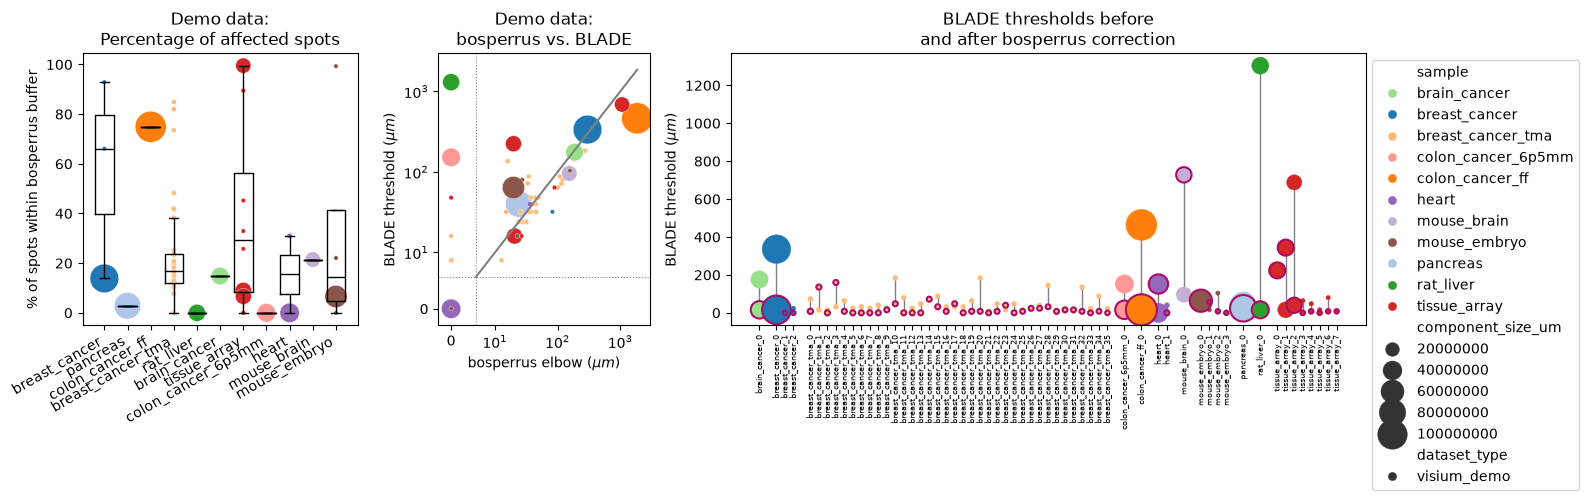

In [7]:
def plot_blade_vs_bosperrus(ax, df, title, zero_pos=2.0, sep=5.0):
    """Panel b: bosperrus elbow vs. BLADE threshold on log-log axes. A missing
    buffer -- no border effect (elbow None/NaN) or BLADE = 0 -- is drawn at a
    stand-in position labelled "0" (zero_pos, left of/below the smallest real
    values, ~9um elbow / 8um BLADE), separated from them by dotted lines at sep."""
    d = df.assign(bsp_plot=df["bsp_thresh_um"].fillna(zero_pos),
                  blade_plot=df["blade_thresh_um"].replace(0, zero_pos))
    sns.scatterplot(d, y="blade_plot", x="bsp_plot", style="dataset_type", hue="sample", size="component_size_um", markers=DATASET_TYPE_MARKERS, sizes=(10, 500), palette=sample_pal, ax=ax, legend=False)
    max_val = np.nanmax(df[["blade_thresh_um", "bsp_thresh_um"]].values)
    ax.plot((sep, max_val), (sep, max_val), c="gray", ls="-")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axvline(sep, color="gray", ls=":", lw=0.8)
    ax.axhline(sep, color="gray", ls=":", lw=0.8)
    ticks = [zero_pos] + [t for t in [10, 100, 1000] if t <= max_val * 1.5]
    labels = ["0"] + [f"$10^{{{int(np.log10(t))}}}$" for t in ticks[1:]]
    ax.set_xticks(ticks, labels)
    ax.set_yticks(ticks, labels)
    ax.minorticks_off()
    ax.set_xlim(zero_pos / 1.6, max_val * 1.6)
    ax.set_ylim(zero_pos / 1.6, max_val * 1.6)
    ax.set_title(title)
    ax.set_ylabel("BLADE threshold ($\\mu m$)")
    ax.set_xlabel("bosperrus elbow ($\\mu m$)")



f, axs = plt.subplots(1, 3, figsize=(16, 4.5), width_ratios=[1.3, 1, 3])
axs = axs.reshape(1, 3)  # keep the [0, j] indexing of the panel code

# a: Demo data only. Which percentage of spots would need to be excluded according to bosperrus.
sns.boxplot(demo_results_df, x="sample", y="pct_affected", color="black", fill=False, showfliers=False, linewidth=1, ax=axs[0, 0])
sns.scatterplot(demo_results_df,  x="sample", y="pct_affected", style="dataset_type", hue="sample", size="component_size_um", markers=DATASET_TYPE_MARKERS, sizes=(10, 500), palette=sample_pal, ax=axs[0, 0], legend=False)
axs[0, 0].set_ylabel("% of spots within bosperrus buffer")
axs[0, 0].set_xlabel("")
axs[0, 0].set_title("Demo data:\nPercentage of affected spots")
axs[0, 0].set_xticks(axs[0, 0].get_xticks(), axs[0, 0].get_xticklabels(), rotation=30, ha="right")

# b: Demo data only. Agreement of BLADE and bosperrus (no border effect / BLADE = 0 shown at "0").
plot_blade_vs_bosperrus(axs[0, 1], demo_results_df, "Demo data:\nbosperrus vs. BLADE")

# c: Demo data only. Bosperrus correction decreases BLADE identified buffer. 
for _, row in figure2_df.iterrows():
    axs[0, 2].plot([row["x_pos"], row["x_pos"]], [row["blade_thresh_um"], row["blade_thresh_corrected_um"]], color="gray", linewidth=1, zorder=0)

sns.scatterplot(data=figure2_df, x="x_pos", y="blade_thresh_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=None, legend=True, ax=axs[0, 2], zorder=2)
sns.scatterplot(data=figure2_df, x="x_pos", y="blade_thresh_corrected_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=FIT_PALETTE["Exponential Saturation Fit"], linewidth=1.5, legend=False, ax=axs[0, 2], zorder=2)

axs[0, 2].set_xticks(x_pos)
axs[0, 2].set_xticklabels(figure2_df["component_label"], rotation=90, fontsize=6)

axs[0, 2].set_xlabel("")
axs[0, 2].set_ylabel("BLADE threshold ($\\mu m$)")
axs[0, 2].set_title("BLADE thresholds before\nand after bosperrus correction")

#axs[0, 2].set_yscale("log")
sns.move_legend(axs[0, 2], "upper left", bbox_to_anchor=(1, 1))



plt.tight_layout()
plt.show()

# Diffusion outside the image mask, per demo sample

Pooled, component-free fit (ConstantFit vs. ExponentialDecayFit) on every raw 8 µm bin outside the
image-only H&E mask, zero-count bins included (`bosperrus.quantify_diffusion_from_raw`). The
cross-technology comparison of these fits is in `ST_paired.ipynb`.

In [8]:
raw_pooled_df = pd.DataFrame([
    json.loads((RESULTS_DIR / f"{sample}_diffusion_8um.json").read_text()) for sample in SAMPLES["name"]
])
raw_pooled_df["1/beta"] = raw_pooled_df["decay_length_um"]
raw_pooled_df[["sample", "best_fit_type", "alpha", "beta", "1/beta", "perc_counts_outside", "mask_tissue_fraction", "n_bins_total"]]

,sample,best_fit_type,alpha,beta,1/beta,perc_counts_outside,mask_tissue_fraction,n_bins_total
0,breast_cancer,Exponential Decay Fit,0.770112,0.003318,301.390902,1.494570,0.662315,1907161
1,pancreas,Exponential Decay Fit,18.204205,0.151226,6.612629,0.459399,0.706663,1907161
2,colon_cancer_ff,Exponential Decay Fit,3.524541,0.004612,216.838091,0.865921,0.710763,1907161
3,breast_cancer_tma,Exponential Decay Fit,0.748499,0.033595,29.766726,7.601562,0.174952,1907161
4,rat_liver,Exponential Decay Fit,9.516199,0.153052,6.533730,0.478478,0.353904,702244
5,brain_cancer,Exponential Decay Fit,1.776298,0.065835,15.189472,0.864025,0.595999,702244
6,tissue_array,Exponential Decay Fit,0.836362,0.050677,19.732729,1.427731,0.513489,1907161
7,colon_cancer_6p5mm,Exponential Decay Fit,1.117441,0.082162,12.171015,0.318803,0.415440,702244
8,heart,Exponential Decay Fit,0.747804,0.027907,35.832974,0.751588,0.504584,702244
9,mouse_brain,Exponential Decay Fit,5.061060,0.105663,9.464068,1.919682,0.681510,702244


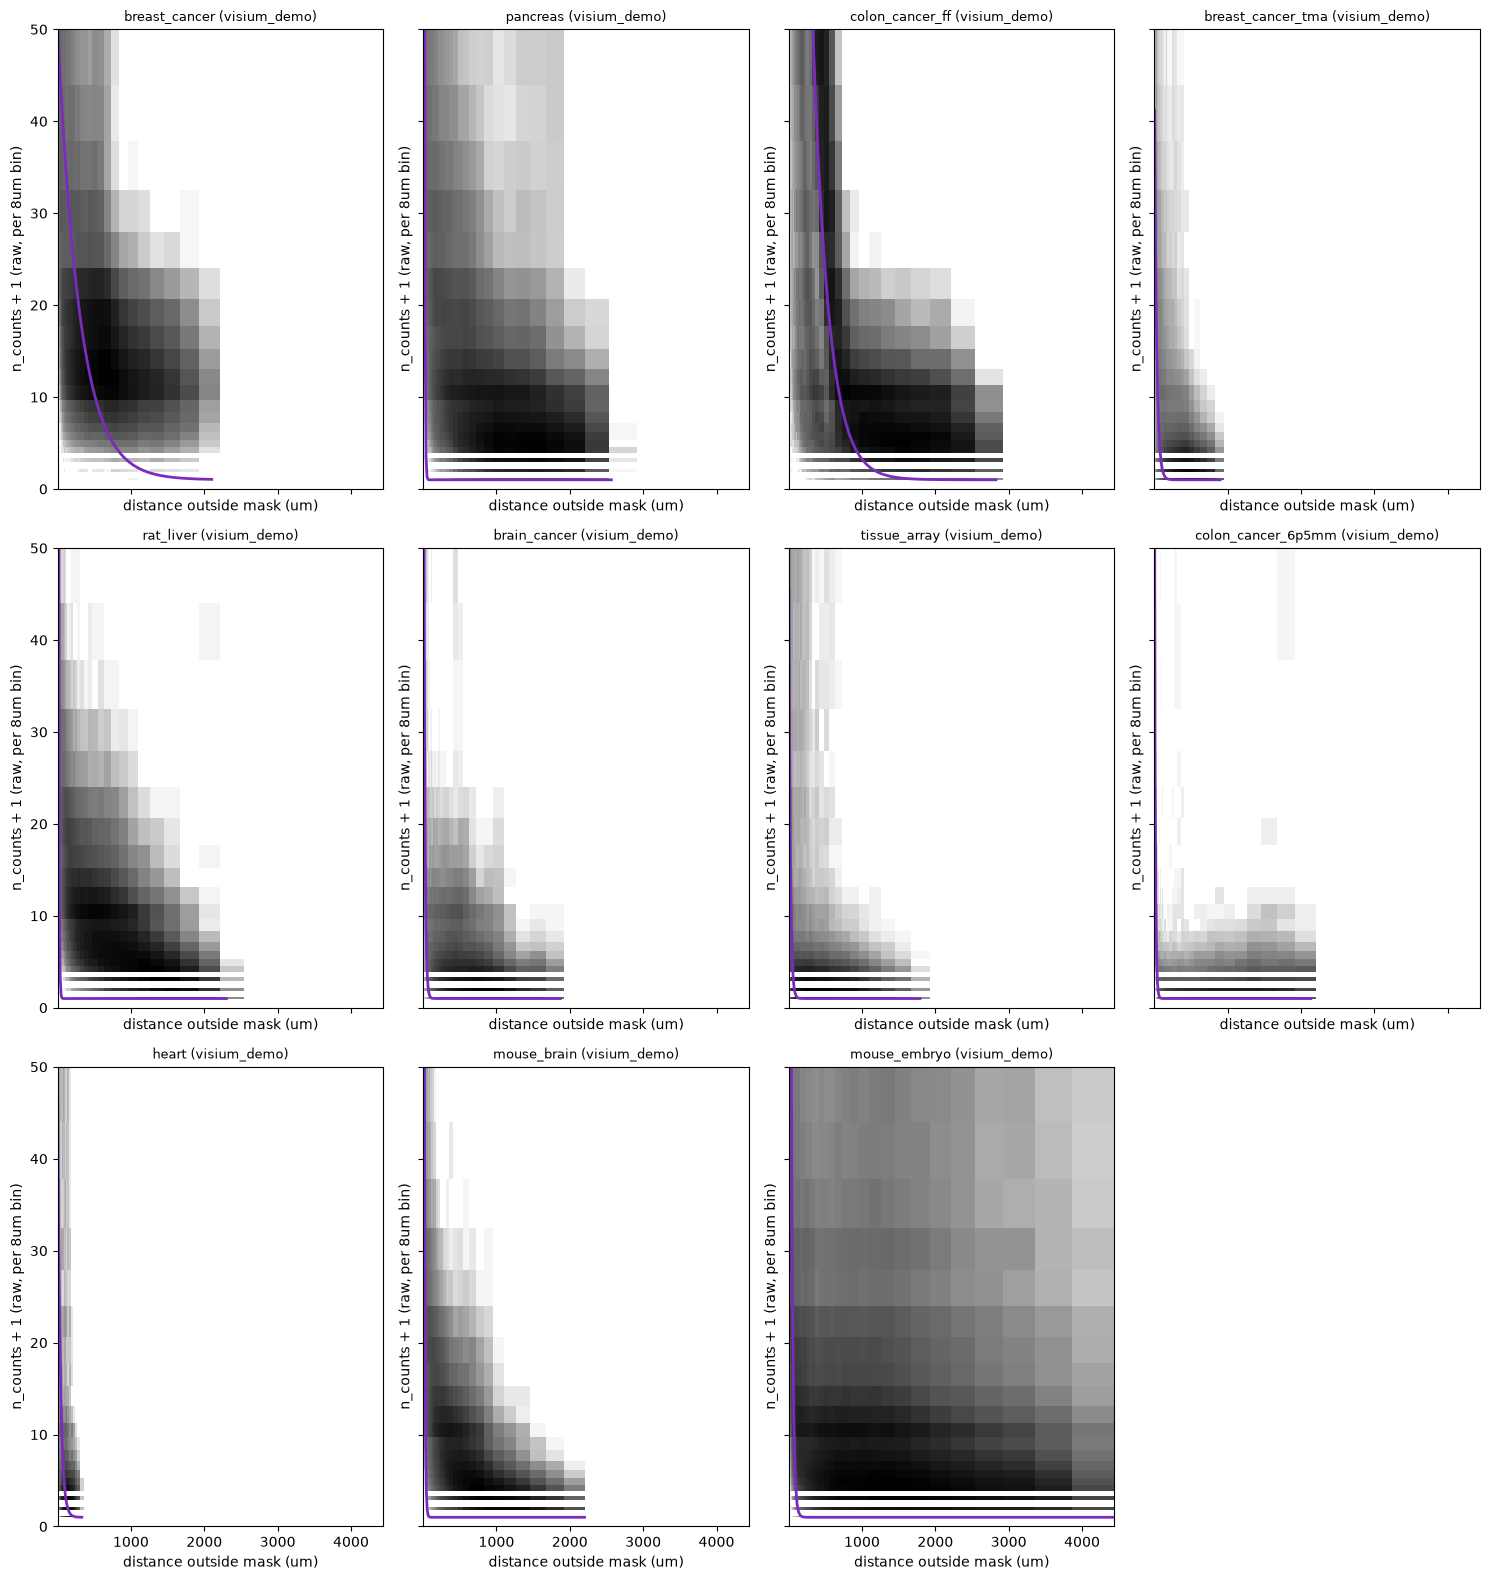

In [9]:
# One bosperrus.plot_fit per sample: the pooled diffusion fit (ConstantFit vs.
# ExponentialDecayFit on every raw 8um bin outside the mask, zero-count bins
# included -- the fit behind panels e/f) over its own 2D histogram.
#
# The curve uses the fitted per-bin amplitude a (params["exponential_decay_a"]),
# not alpha: alpha = a / bin area is the cross-resolution-comparable number, but
# the histogram shows counts per bin.
#
# Shared bin EDGES across all subplots, so a given (distance, n_counts) cell means
# the same range everywhere. n_counts+1 so zero-count bins (most bins far from the
# tissue) stay visible on a log axis.
all_distance, all_counts = [], []
for sample in raw_pooled_df["sample"]:
    pts = np.load(RESULTS_DIR / f"{sample}_diffusion_8um.npz")
    outside = pts["distance_um"] > 0
    all_distance.append(pts["distance_um"][outside])
    all_counts.append(pts["n_counts"][outside])
all_distance, all_counts = np.concatenate(all_distance), np.concatenate(all_counts) + 1

N_BINS = 60
x_edges = np.logspace(np.log10(all_distance.min()), np.log10(all_distance.max()), N_BINS + 1)
y_edges = np.logspace(np.log10(all_counts.min()), np.log10(all_counts.max()), N_BINS + 1)
del all_distance, all_counts

N_COLS = 4
N_ROWS = int(np.ceil(len(raw_pooled_df) / N_COLS))
fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(15, 5.3 * N_ROWS), sharex=True, sharey=True, squeeze=False)
for ax in axes.flat[len(raw_pooled_df):]:
    ax.set_visible(False)
for ax, (_, row) in zip(axes.flat, raw_pooled_df.iterrows()):
    pts = np.load(RESULTS_DIR / f"{row['sample']}_diffusion_8um.npz")
    distance, n_counts = pts["distance_um"], pts["n_counts"]
    outside = distance > 0

    params = row["params"]
    if row["best_fit_type"] == "Exponential Decay Fit":
        a, b = params["exponential_decay_a"], params["exponential_decay_b"]
        predict_fn = lambda d, a=a, b=b: a * np.exp(-b * d) + 1  # +1 to match the n_counts+1 shift below
    else:  # ConstantFit baseline won instead
        c = params["constant_c"] + 1
        predict_fn = lambda d, c=c: np.full_like(d, c)

    plot_fit(ax, distance[outside], n_counts[outside] + 1, predict_fn, bins=[x_edges, y_edges],
             line_kwargs={"color": FIT_PALETTE.get(row["best_fit_type"], "red")})
    #ax.set_xscale("log")
    #ax.set_yscale("log")
    ax.set_title(f"{row['sample']} ({row['dataset_type']})", fontsize=9)
    ax.set_xlabel("distance outside mask (um)")
    ax.set_ylabel("n_counts + 1 (raw, per 8um bin)")
    ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()

# Supplement: panels a-c with the image mask as tissue footprint

Same border analysis as Part 1 (n_counts > 0, holes <= 1024 um^2 filled, components > 1000 bins,
bosperrus elbow, BLADE raw and corrected), but the input bins are the **raw 8um bins inside the
image-only tissue mask** (the same mask as panels e/f: Otsu on the hires H&E) instead of Space Ranger's
`in_tissue`. Computed by `src/spatial_omics/st_precompute.py <sample> --image-mask`
(`*_buffer_imagemask.json`).

                    pct_affected  bsp_thresh_um  blade_thresh_um
sample                                                          
brain_cancer                17.8          221.3            160.0
breast_cancer               60.0           28.8             32.0
breast_cancer_tma           10.1           30.7             32.0
colon_cancer_6p5mm           0.0            NaN            160.0
colon_cancer_ff             75.9         2685.6           2000.0
heart                       10.5           28.8            824.0
mouse_brain                 20.7          153.7             96.0
mouse_embryo                12.5            9.6             48.0
pancreas                     0.0            NaN           1240.0
rat_liver                    0.0            NaN           1240.0
tissue_array                 0.0          477.8             32.0


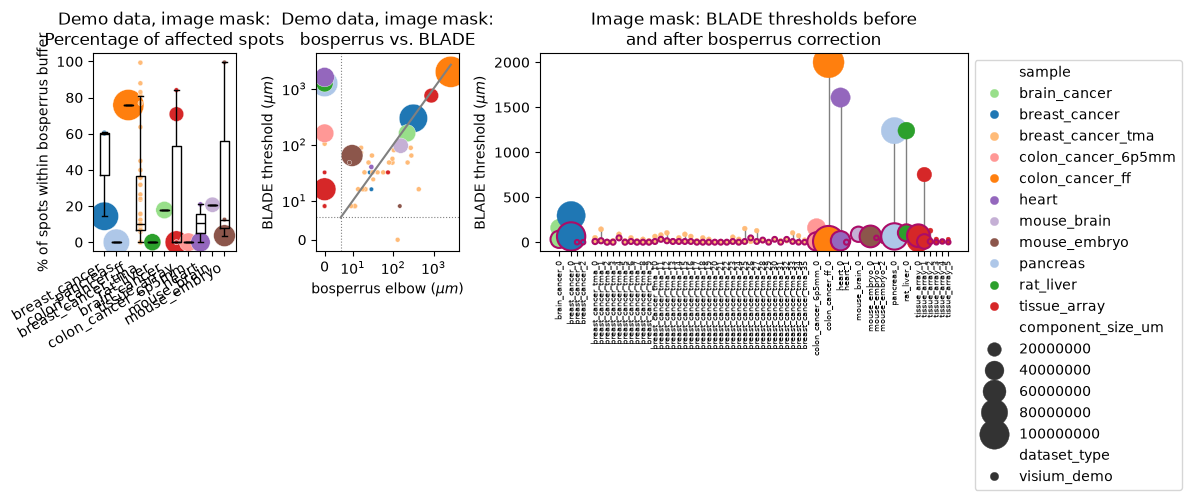

In [10]:
def load_buffer_results(suffix=""):
    """Per-component results table (same columns as cells 5-6) from {sample}_buffer{suffix}.json."""
    rows = []
    for sample in SAMPLES["name"]:
        buf = json.loads((RESULTS_DIR / f"{sample}_buffer{suffix}.json").read_text())
        bin_size_um = buf["resolution_um"]
        for label, info in buf["per_component"].items():
            bsp_thresh_um = _nan(info["bsp_thresh_um"])
            rows.append([
                sample, int(label), f"{sample}_{label}", info["n_spots"],
                _nan(info["blade_thresh"]), bsp_thresh_um / bin_size_um, _nan(info["blade_thresh_corrected"]),
                bin_size_um,
                _nan(info["blade_thresh_um"]), bsp_thresh_um, _nan(info["blade_thresh_corrected_um"]),
                info["pct_affected"],
            ])
    df = pd.DataFrame(rows, columns=results_df.columns[:12])
    df = df.merge(SAMPLES[["name", "dataset_type"]], left_on="sample", right_on="name")
    df["component_size_um"] = df["component_size"] * df["bin_size_um"] ** 2
    return df


im_results_df = load_buffer_results("_imagemask")
im_demo_df = im_results_df[im_results_df["dataset_type"] == "visium_demo"]

im_figure_df = im_demo_df.sort_values(["dataset_type", "sample", "component_rank"]).reset_index(drop=True)
im_x_pos, x, previous_sample = [], 0, None
for _, row in im_figure_df.iterrows():
    if previous_sample is not None:
        x += sample_gap if row["sample"] != previous_sample else component_spacing
    im_x_pos.append(x)
    previous_sample = row["sample"]
im_x_pos = np.array(im_x_pos)
im_figure_df["x_pos"] = im_x_pos

print(im_demo_df.groupby("sample")[["pct_affected", "bsp_thresh_um", "blade_thresh_um"]].median().round(1))

f, axs = plt.subplots(1, 3, figsize=(12, 4), width_ratios=[1, 1, 3])

# a: % of bins within the bosperrus buffer
sns.boxplot(im_demo_df, x="sample", y="pct_affected", color="black", fill=False, showfliers=False, linewidth=1, ax=axs[0])
sns.scatterplot(im_demo_df, x="sample", y="pct_affected", style="dataset_type", hue="sample", size="component_size_um", markers=DATASET_TYPE_MARKERS, sizes=(10, 500), palette=sample_pal, ax=axs[0], legend=False)
axs[0].set_ylabel("% of spots within bosperrus buffer")
axs[0].set_xlabel("")
axs[0].set_title("Demo data, image mask:\nPercentage of affected spots")
axs[0].set_xticks(axs[0].get_xticks(), axs[0].get_xticklabels(), rotation=30, ha="right")

# b: bosperrus elbow vs. BLADE (no border effect / BLADE = 0 shown at "0"; plot_blade_vs_bosperrus from the main figure cell)
plot_blade_vs_bosperrus(axs[1], im_demo_df, "Demo data, image mask:\nbosperrus vs. BLADE")

# c: BLADE before vs. after bosperrus correction
for _, row in im_figure_df.iterrows():
    axs[2].plot([row["x_pos"], row["x_pos"]], [row["blade_thresh_um"], row["blade_thresh_corrected_um"]], color="gray", linewidth=1, zorder=0)
sns.scatterplot(data=im_figure_df, x="x_pos", y="blade_thresh_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=None, legend=True, ax=axs[2], zorder=2)
sns.scatterplot(data=im_figure_df, x="x_pos", y="blade_thresh_corrected_um", hue="sample", style="dataset_type", markers=DATASET_TYPE_MARKERS, palette=sample_pal, sizes=(10, 500), size="component_size_um", edgecolor=FIT_PALETTE["Exponential Saturation Fit"], linewidth=1.5, legend=False, ax=axs[2], zorder=2)
axs[2].set_xticks(im_x_pos)
axs[2].set_xticklabels(im_figure_df["component_label"], rotation=90, fontsize=6)
axs[2].set_xlabel("")
axs[2].set_ylabel("BLADE threshold ($\\mu m$)")
axs[2].set_title("Image mask: BLADE thresholds before\nand after bosperrus correction")
sns.move_legend(axs[2], "upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
Path("../../result_plots/spatial_omics").mkdir(parents=True, exist_ok=True)
plt.savefig("../../result_plots/spatial_omics/ST_panels_abc_image_mask.svg", bbox_inches="tight")
plt.show()